# Banking Financial Performance & Risk Analysis
Project by: Antung Fatimah

Analisis indikator **NPL, ROA, CAR, LDR** (+ NIM sebagai pembanding) industri perbankan Indonesia, Januari 2018 – Juni 2025, data bulanan agregat (rujukan: Statistik Perbankan Indonesia, OJK).



## 1. Import dan Pengaturan
Memuat library (pandas, numpy, matplotlib) dan menentukan ambang batas acuan: NPL maks 5%, CAR min 8%, dan kisaran LDR sehat 84–94%. Ambang batas ini asumsi.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "spi_bulanan_repaired_v2.csv"
os.makedirs("figures", exist_ok=True)

# Ambang batas acuan (sesuaikan dengan ketentuan OJK/BI terbaru)
NPL_MAX = 5.0                    # NPL gross maks 5%
CAR_MIN = 8.0                    # CAR minimum 8%
LDR_LOW, LDR_HIGH = 84.0, 94.0   # kisaran sehat LDR/LFR (asumsi)

# Rezim periode (definisi sendiri, jelaskan di README)
REGIMES = [("Pra-COVID", "2018-01", "2020-02"),
           ("COVID",     "2020-03", "2021-12"),
           ("Pemulihan", "2022-01", "2025-06")]

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150)
    plt.show()

## 2. Load dan Cleaning Data
Sebelum analisis, data dicek dulu: bulan yang hilang, nilai di luar batas wajar, dan nilai yang terduplikasi.

In [2]:
raw = pd.read_csv(DATA_PATH)
raw = raw.rename(columns={"Periode": "periode", "NPL_Gross_%": "NPL", "ROA_%": "ROA",
                          "CAR_%": "CAR", "LDR_%": "LDR", "NIM_%": "NIM"})
raw["periode"] = pd.to_datetime(raw["periode"] + "-01")
raw = raw.drop(columns=["Tahun", "Bulan", "Sumber_NPL_SPI", "Sumber_SPI"]).sort_values("periode").reset_index(drop=True)
INDS = ["NPL", "ROA", "CAR", "LDR", "NIM"]

print(f"Baris: {len(raw)} | {raw.periode.min():%Y-%m} s.d. {raw.periode.max():%Y-%m}")

# baris bulan yang hilang
full = pd.date_range(raw.periode.min(), raw.periode.max(), freq="MS")
missing = full.difference(raw.periode)
print("Bulan hilang (baris tidak ada):", [f"{d:%Y-%m}" for d in missing] or "tidak ada")

# nilai kosong per indikator, dan nol yang dipakai sebagai placeholder
print("NaN per indikator:", raw[INDS].isna().sum().to_dict())
print("Nilai 0 (placeholder):", int((raw[INDS] == 0).sum().sum()))
na_rows = raw[raw[INDS].isna().any(axis=1)]
print("Bulan dengan nilai kosong:", [f"{d:%Y-%m}" for d in na_rows.periode])

# 3) nilai di luar batas wajar (aturan plausibilitas sederhana untuk industri perbankan agregat)
implausible = (raw.ROA > 5) | (raw.CAR > 60) | (raw.LDR > 150) | (raw.NIM > 10)
print("Baris tidak wajar:", [f"{d:%Y-%m}" for d in raw.loc[implausible, "periode"]] or "tidak ada")

# nilai yang persis sama di bulan berbeda (indikasi salin-tempel)
dup = raw[raw.assign(k=raw.NPL.round(6)).duplicated("k", keep=False)][["periode", "NPL"]]
print("NPL identik di bulan berbeda:")
print(dup.set_index("periode").round(6).to_string() if len(dup) else "tidak ada")

Baris: 90 | 2018-01 s.d. 2025-06
Bulan hilang (baris tidak ada): tidak ada
NaN per indikator: {'NPL': 0, 'ROA': 4, 'CAR': 4, 'LDR': 4, 'NIM': 4}
Nilai 0 (placeholder): 0
Bulan dengan nilai kosong: ['2021-06', '2021-07', '2021-08', '2021-09']
Baris tidak wajar: tidak ada
NPL identik di bulan berbeda:
tidak ada


In [3]:
print("Bulan dengan nilai kosong (NPL tersedia, indikator lain tidak):")
print(raw.loc[raw[INDS].isna().any(axis=1)].set_index("periode").round(2).to_string())

Bulan dengan nilai kosong (NPL tersedia, indikator lain tidak):
             NPL  ROA  CAR  LDR  NIM
periode                             
2021-06-01  3.24  NaN  NaN  NaN  NaN
2021-07-01  3.35  NaN  NaN  NaN  NaN
2021-08-01  3.35  NaN  NaN  NaN  NaN
2021-09-01  3.22  NaN  NaN  NaN  NaN


In [5]:
# presisi desimal: OJK mempublikasikan rasio dengan 2 desimal (sel kosong tidak dihitung)
valid = raw[INDS].notna()
two_dec = ((raw[INDS].round(2) - raw[INDS]).abs() < 1e-9) & valid
print(f"Nilai dengan <=2 desimal: {int(two_dec.values.sum())} dari {int(valid.values.sum())} sel terisi")
print(f"Baris dengan semua nilai terisi <=2 desimal: {int((two_dec | ~valid).all(axis=1).sum())} dari {len(raw)}")

Nilai dengan <=2 desimal: 16 dari 434 sel terisi
Baris dengan semua nilai terisi <=2 desimal: 0 dari 90


Note: Data bulanan lengkap Januari 2018 – Juni 2025 (90 bulan), tanpa bulan yang hilang, tanpa nilai NPL yang identik di bulan berbeda, dan tanpa nilai di luar batas wajar. Empat bulan (Jun–Sep 2021) tidak memiliki data ROA, CAR, LDR, dan NIM (NPL tersedia). Bulan-bulan itu dibiarkan kosong dan tidak diinterpolasi, sehingga garis pada grafik terputus di periode tersebut dan statistik dihitung dari bulan yang terisi (86 bulan untuk keempat indikator itu). Kolom sumber mencatat bulan-bulan itu berasal dari file SPI Juni 2022; angkanya belum diisi.  Ada selisih kecil pada beberapa bulan (mis. CAR Mar 2023: 24,81 di data vs 24,69 di siaran pers). Deret bulanan ini hasil olahan dari file SPI.

In [6]:
df = raw.copy()
df[INDS] = df[INDS].replace(0, np.nan)   # jaga-jaga: nol bukan nilai valid untuk indikator ini
df = df.set_index("periode").reindex(pd.date_range("2018-01-01", "2025-06-01", freq="MS"))
df.index.name = "periode"
df["tahun"] = df.index.year
print(f"Data analisis: {len(df)} bulan | lengkap untuk semua indikator: {df[INDS].dropna().shape[0]} bulan")

Data analisis: 90 bulan | lengkap untuk semua indikator: 86 bulan


## 3. Statistik Deskriptif & Perubahan Antarperiode
Menghitung perubahan NPL, ROA, CAR, dan LDR dari periode ke periode (dalam poin persentase) dan menampilkan statistik ringkas (rata-rata, minimum, maksimum) untuk melihat gambaran umum data.

In [7]:
print(df[INDS].describe().round(2).to_string())
print()
print("Rata-rata tahunan:")
print(df.groupby("tahun")[INDS].mean().round(2).to_string())

         NPL    ROA    CAR    LDR    NIM
count  90.00  86.00  86.00  86.00  86.00
mean    2.70   2.42  24.70  86.48   4.72
std     0.35   0.30   1.71   5.56   0.22
min     2.08   1.59  21.67  77.13   4.31
25%     2.44   2.35  23.25  81.86   4.54
50%     2.66   2.49  24.62  86.07   4.70
75%     3.00   2.62  25.97  92.42   4.89
max     3.35   3.02  27.86  96.19   5.19

Rata-rata tahunan:
        NPL   ROA    CAR    LDR   NIM
tahun                                
2018   2.71  2.47  22.78  92.20  5.11
2019   2.60  2.49  23.29  94.41  4.89
2020   3.03  2.05  22.97  87.96  4.51
2021   3.22  1.92  24.76  80.00  4.58
2022   2.87  2.41  25.15  79.84  4.66
2023   2.46  2.76  26.66  82.37  4.82
2024   2.26  2.65  26.67  85.90  4.58
2025   2.22  2.49  26.01  87.61  4.46


## 4. Visualisasi Tren
Menghitung perubahan NPL, ROA, CAR, dan LDR dari periode ke periode (dalam poin persentase), lalu menampilkan statistik ringkas (rata-rata, minimum, maksimum) untuk melihat gambaran umum data.


Note: Area abu-abu = periode COVID (Mar 2020 – Des 2021).
Celah pada garis ROA, CAR, dan LDR = Jun–Sep 2021 (data tidak tersedia).

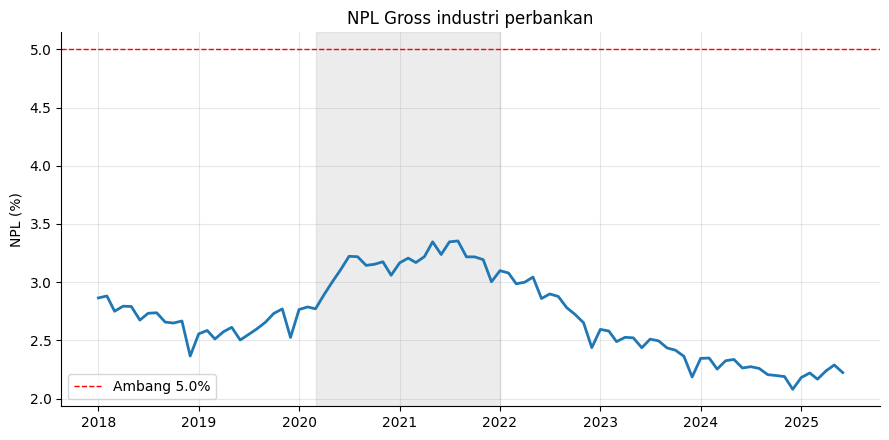

In [8]:
def trend(col, title, hline=None, band=None, name=None):
    fig, ax = plt.subplots()
    ax.plot(df.index, df[col], lw=2, color="tab:blue")
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="grey", alpha=0.15)
    if hline is not None:
        ax.axhline(hline, color="red", ls="--", lw=1, label=f"Ambang {hline}%")
        ax.legend()
    if band is not None:
        ax.axhspan(*band, color="green", alpha=0.10, label=f"Kisaran {band[0]:.0f}-{band[1]:.0f}%")
        ax.legend()
    ax.set(title=title, ylabel=f"{col} (%)")
    save(name or col.lower())

trend("NPL", "NPL Gross industri perbankan", hline=NPL_MAX, name="npl")

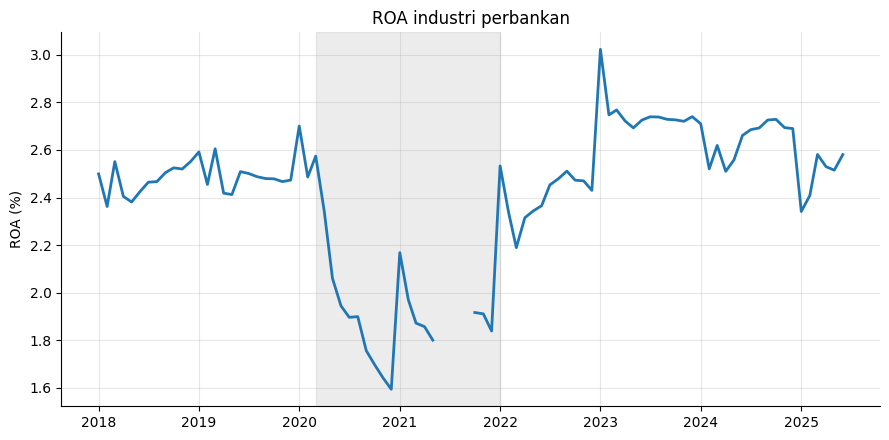

In [9]:
trend("ROA", "ROA industri perbankan", name="roa")

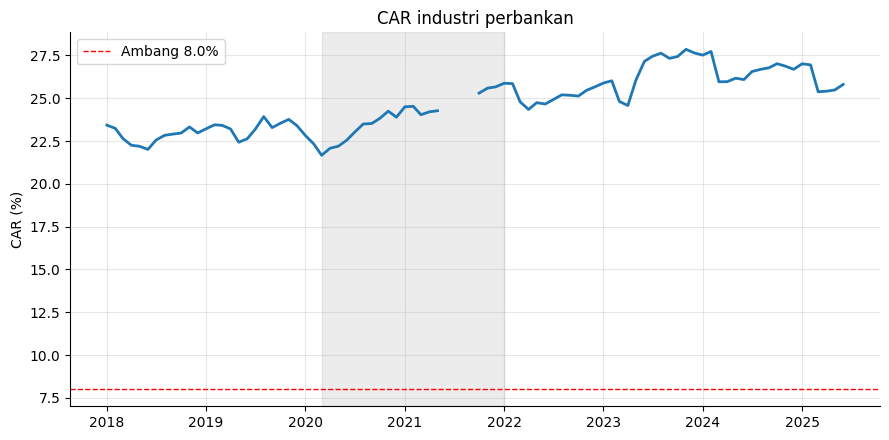

In [10]:
trend("CAR", "CAR industri perbankan", hline=CAR_MIN, name="car")

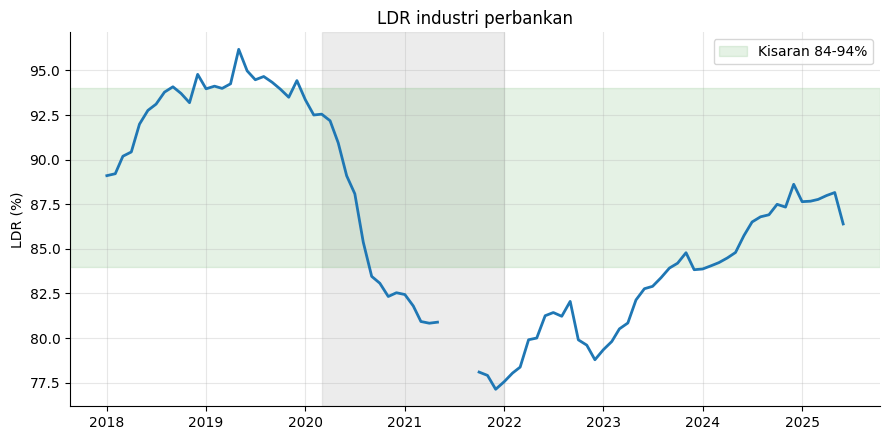

In [11]:
trend("LDR", "LDR industri perbankan", band=(LDR_LOW, LDR_HIGH), name="ldr")

## 5. Perbandingan per Rezim Periode

In [12]:
def regime_of(ts):
    for name, a, b in REGIMES:
        if pd.Timestamp(a) <= ts <= pd.Timestamp(b) + pd.offsets.MonthEnd(0):
            return name
df["rezim"] = [regime_of(t) for t in df.index]
order = [r[0] for r in REGIMES]
reg = df.groupby("rezim")[INDS].mean().loc[order]
print(reg.round(2).to_string())
print()
print("Selisih Pemulihan vs Pra-COVID (poin persentase):")
print((reg.loc["Pemulihan"] - reg.loc["Pra-COVID"]).round(2).to_string())

            NPL   ROA    CAR    LDR   NIM
rezim                                    
Pra-COVID  2.67  2.49  23.00  93.27  4.99
COVID      3.16  1.93  23.81  83.87  4.50
Pemulihan  2.49  2.59  26.14  83.40  4.65

Selisih Pemulihan vs Pra-COVID (poin persentase):
NPL   -0.18
ROA    0.10
CAR    3.14
LDR   -9.87
NIM   -0.34


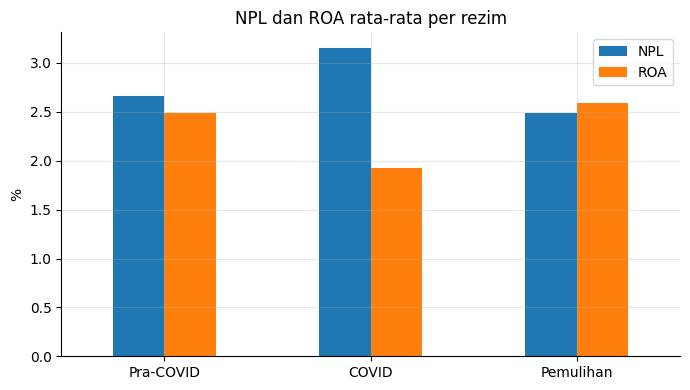

In [13]:
ax = reg[["NPL", "ROA"]].plot(kind="bar", figsize=(7, 4), rot=0)
ax.set(title="NPL dan ROA rata-rata per rezim", ylabel="%", xlabel="")
save("rezim_npl_roa")

## 6. CAR vs LDR
CAR jauh di atas minimum, jadi yang menarik adalah bagaimana permodalan bergerak berlawanan dengan LDR.

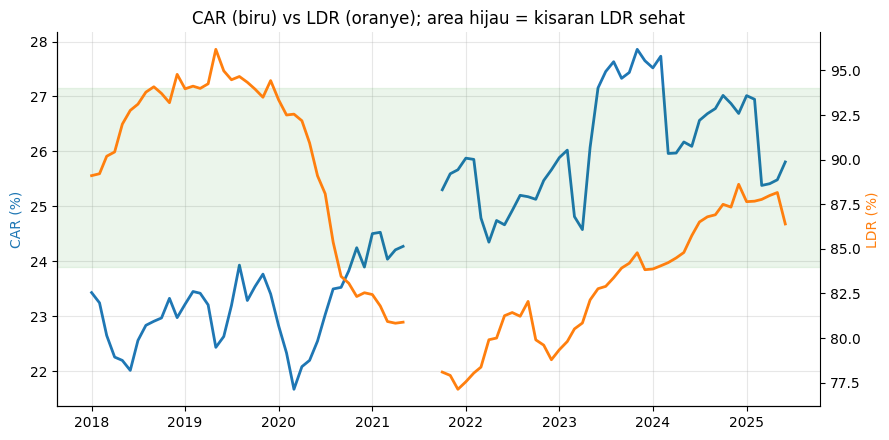

Korelasi CAR-LDR (level): -0.58


In [14]:
fig, ax1 = plt.subplots()
ax1.plot(df.index, df["CAR"], color="tab:blue", lw=2)
ax1.set_ylabel("CAR (%)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(df.index, df["LDR"], color="tab:orange", lw=2)
ax2.axhspan(LDR_LOW, LDR_HIGH, color="green", alpha=0.08)
ax2.set_ylabel("LDR (%)", color="tab:orange"); ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax1.set_title("CAR (biru) vs LDR (oranye); area hijau = kisaran LDR sehat")
save("car_vs_ldr")
print(f"Korelasi CAR-LDR (level): {df['CAR'].corr(df['LDR']):.2f}")

## 7. Hubungan NPL dan ROA
Dua deret waktu yang sama-sama bertren bisa tampak berkorelasi kuat hanya karena trennya (*spurious correlation*). Karena itu korelasi dihitung dua cara: pada **level** dan pada **perubahan bulanan** (selisih pertama).

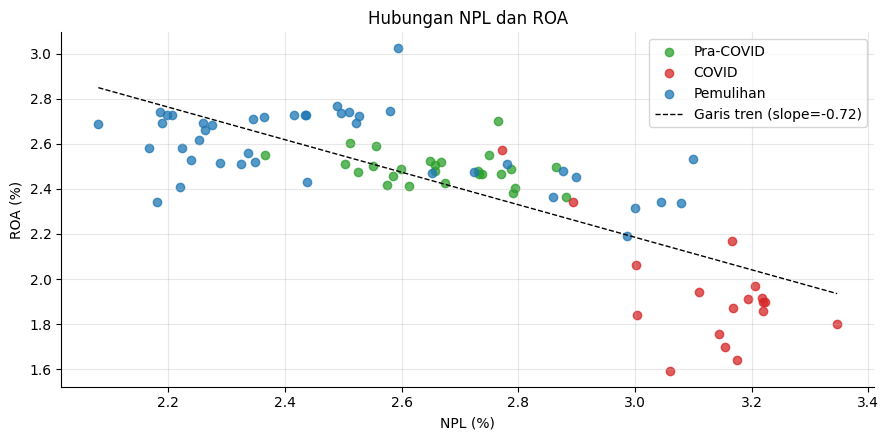

Korelasi NPL-ROA, level              : -0.79
Korelasi NPL-ROA, perubahan bulanan  : 0.05
Slope regresi: tiap NPL naik 1 poin, ROA rata-rata berubah -0.72 poin (R^2 = 0.62)


In [15]:
d = df[["NPL", "ROA", "rezim"]].dropna()
colors = {"Pra-COVID": "tab:green", "COVID": "tab:red", "Pemulihan": "tab:blue"}
fig, ax = plt.subplots()
for r in order:
    g = d[d.rezim == r]
    ax.scatter(g["NPL"], g["ROA"], alpha=0.75, label=r, color=colors[r])
m, b = np.polyfit(d["NPL"], d["ROA"], 1)
xs = np.linspace(d["NPL"].min(), d["NPL"].max(), 50)
ax.plot(xs, m * xs + b, "k--", lw=1, label=f"Garis tren (slope={m:.2f})")
ax.set(title="Hubungan NPL dan ROA", xlabel="NPL (%)", ylabel="ROA (%)"); ax.legend()
save("npl_vs_roa")

lvl = df["NPL"].corr(df["ROA"])
chg = df["NPL"].diff().corr(df["ROA"].diff())
print(f"Korelasi NPL-ROA, level              : {lvl:.2f}")
print(f"Korelasi NPL-ROA, perubahan bulanan  : {chg:.2f}")
print(f"Slope regresi: tiap NPL naik 1 poin, ROA rata-rata berubah {m:.2f} poin (R^2 = {lvl**2:.2f})")

In [16]:
# Apakah NPL 'mendahului' ROA? korelasi ROA(t) dengan NPL(t-k)
rows = []
for k in [0, 1, 3, 6, 9, 12]:
    rows.append({"lag NPL (bulan)": k, "korelasi dengan ROA": df["NPL"].shift(k).corr(df["ROA"])})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 lag NPL (bulan)  korelasi dengan ROA
               0                -0.79
               1                -0.79
               3                -0.72
               6                -0.55
               9                -0.37
              12                -0.13


In [17]:
print("Matriks korelasi (level):")
print(df[INDS].corr().round(2).to_string())
print()
print("Matriks korelasi (perubahan bulanan):")
print(df[INDS].diff().corr().round(2).to_string())

Matriks korelasi (level):
      NPL   ROA   CAR   LDR   NIM
NPL  1.00 -0.79 -0.50 -0.27 -0.12
ROA -0.79  1.00  0.36  0.22  0.41
CAR -0.50  0.36  1.00 -0.58 -0.36
LDR -0.27  0.22 -0.58  1.00  0.51
NIM -0.12  0.41 -0.36  0.51  1.00

Matriks korelasi (perubahan bulanan):
      NPL   ROA   CAR   LDR   NIM
NPL  1.00  0.05  0.24 -0.22 -0.10
ROA  0.05  1.00 -0.02  0.19  0.39
CAR  0.24 -0.02  1.00 -0.16 -0.00
LDR -0.22  0.19 -0.16  1.00  0.17
NIM -0.10  0.39 -0.00  0.17  1.00


## 8. Flag Risiko terhadap Ambang Batas

In [18]:
ok = df.dropna(subset=INDS)
print(f"NPL tertinggi : {df.NPL.max():.2f}% ({df.NPL.idxmax():%Y-%m}) | headroom ke batas {NPL_MAX}%: {NPL_MAX - df.NPL.max():.2f} pp")
print(f"CAR terendah  : {ok.CAR.min():.2f}% ({ok.CAR.idxmin():%Y-%m}) | headroom ke minimum {CAR_MIN}%: {ok.CAR.min() - CAR_MIN:.2f} pp")
below = (ok.LDR < LDR_LOW).sum(); above = (ok.LDR > LDR_HIGH).sum()
print(f"LDR di bawah {LDR_LOW:.0f}%: {below} bulan | di atas {LDR_HIGH:.0f}%: {above} bulan | dalam kisaran: {len(ok) - below - above} bulan (dari {len(ok)})")
print()
low = ok[ok.LDR < LDR_LOW]
span = ok.loc[low.index.min():low.index.max()]
exc = [f"{d:%Y-%m}" for d in span.index[span.LDR >= LDR_LOW]]
print(f"LDR di bawah kisaran: {low.index.min():%Y-%m} s.d. {low.index.max():%Y-%m}")
print("Bulan terisi dalam rentang itu yang tidak di bawah kisaran:", exc or "tidak ada")
print("Bulan LDR di atas kisaran:", f"{ok[ok.LDR > LDR_HIGH].index.min():%Y-%m} s.d. {ok[ok.LDR > LDR_HIGH].index.max():%Y-%m}")

NPL tertinggi : 3.35% (2021-08) | headroom ke batas 5.0%: 1.65 pp
CAR terendah  : 21.67% (2020-03) | headroom ke minimum 8.0%: 13.67 pp
LDR di bawah 84%: 35 bulan | di atas 94%: 10 bulan | dalam kisaran: 41 bulan (dari 86)

LDR di bawah kisaran: 2020-09 s.d. 2024-01
Bulan terisi dalam rentang itu yang tidak di bawah kisaran: ['2023-10', '2023-11']
Bulan LDR di atas kisaran: 2018-09 s.d. 2019-12


## 9. Ringkasan Perubahan

In [19]:
first, last = ok.index.min(), ok.index.max()
print(f"Periode: {first:%Y-%m} s.d. {last:%Y-%m}\n")
for col in INDS:
    a, b = ok.loc[first, col], ok.loc[last, col]
    print(f"{col}: {a:.2f}% -> {b:.2f}%  ({b - a:+.2f} pp)")
print()
print("Puncak/lembah:")
print(f"  NPL puncak {df.NPL.max():.2f}% ({df.NPL.idxmax():%Y-%m}); ROA terendah {ok.ROA.min():.2f}% ({ok.ROA.idxmin():%Y-%m}); "
      f"LDR terendah {ok.LDR.min():.2f}% ({ok.LDR.idxmin():%Y-%m})")

Periode: 2018-01 s.d. 2025-06

NPL: 2.86% -> 2.22%  (-0.64 pp)
ROA: 2.50% -> 2.58%  (+0.08 pp)
CAR: 23.43% -> 25.81%  (+2.38 pp)
LDR: 89.10% -> 86.40%  (-2.71 pp)
NIM: 5.19% -> 4.48%  (-0.70 pp)

Puncak/lembah:
  NPL puncak 3.35% (2021-08); ROA terendah 1.59% (2020-12); LDR terendah 77.13% (2021-12)


## Insight:

1. NPL terkendali. NPL naik dari 2,86% (Jan 2018) ke puncak 3,35% (Agu 2021), lalu turun ke 2,22% (Jun 2025). Jaraknya ke batas 5% tidak pernah kurang dari 1,65 poin.
2. ROA turun saat COVID, lalu pulih. ROA terendah 1,59% (Des 2020). Rata-ratanya 2,49% sebelum COVID, 1,93% saat COVID, dan 2,59% di masa pemulihan.
3. Modal menebal, LDR turun. CAR terendah 21,67% (Mar 2020), masih 13,67 poin di atas minimum 8%, dan naik ke 25,81% (Jun 2025). Rata-rata CAR naik dari 23,00% ke 26,14%, sedangkan rata-rata LDR turun dari 93,27% ke 83,40%. Korelasi CAR dan LDR −0,58.


